# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ezra Abhinaya Pasaribu
- **Email:** psribuezraa@gmail.com
- **ID Dicoding:** ezra_psribu

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana kondisi cuaca (weathersit) dan pergantian musim (season) memengaruhi rata-rata jumlah penyewaan sepeda harian (cnt) sepanjang tahun 2011–2012, dan pada kondisi seperti apa terjadi penurunan sewa paling signifikan?
- **Pertanyaan 2:** Bagaimana perbedaan karakteristik pola peminjaman sepeda per jam antara pengguna kasual dan pengguna terdaftar pada hari kerja dibandingkan hari libur/akhir pekan selama periode 2011–2012?
- **Pertanyaan 3:** Berapa persentase pertumbuhan total penyewaan sepeda dari tahun 2011 ke tahun 2012, dan pada bulan apa terjadi performa penyewaan tertinggi di masing-masing tahun?

## Import Semua Packages/Library yang Digunakan

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## Data Wrangling

### Gathering Data

#### Load df day_df dan hour_df

In [51]:
day_df = pd.read_csv("../proyek_akhir/dataset/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [52]:
hour_df = pd.read_csv("../proyek_akhir/dataset/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [53]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [54]:
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [55]:
day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [56]:
hour_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [57]:
print("Jumlah duplikasi day: ", day_df.duplicated().sum())
day_df.describe()

Jumlah duplikasi day:  0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [58]:
print("Jumlah duplikasi hour: ", hour_df.duplicated().sum())
hour_df.describe()

Jumlah duplikasi hour:  0


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [59]:
# Cek konsistensi matematis
print("Mismatch casual + registered != cnt di day_df:", ((day_df['casual'] + day_df['registered']) != day_df['cnt']).sum())
print("Mismatch casual + registered != cnt di hour_df:", ((hour_df['casual'] + hour_df['registered']) != hour_df['cnt']).sum())

Mismatch casual + registered != cnt di day_df: 0
Mismatch casual + registered != cnt di hour_df: 0


**Insight:**
- Terdapat dua dataset utama yang berhasil dimuat dari sistem *Capital Bikeshare* (Washington D.C., 2011–2012):
  1. `day_df`: Terdiri dari **731 baris** dan **16 kolom**, yang merepresentasikan rekaman data agregasi harian.
  2. `hour_df`: Terdiri dari **17.379 baris** dan **17 kolom** (terdapat tambahan kolom `hr` rentang 0–23), yang merepresentasikan rekaman granularitas per jam.
- Relasi dataset:
  - `day_df` untuk menganalisis tren makro, fluktuasi musiman (*seasonality*), dan dampak cuaca harian secara agregat.
  - `hour_df` untuk mendeteksi dinamika mikro, seperti jam sibuk (*rush hours* / komuter) serta perbedaan pola sewa per jam antara pengguna kasual (*casual*) dan pengguna terdaftar (*registered*).
- Secara umum, kedua tabel memuat informasi lingkungan (musim, cuaca, suhu, kelembaban, kecepatan angin) dan metrik pengguna yang lengkap.

### Assessing Data

#### Identifying Data Types Mismatch, Categorical Encoding, and Feature Normalization Issues

In [60]:
# 1. Menampilkan tipe data kolom yang bermasalah (dteday dan kategorikal)
print("--- Tipe Data Kolom dteday & Kategorikal ---")
print(day_df[['dteday', 'season', 'weathersit', 'weekday', 'workingday']].dtypes)

# 2. Menampilkan representasi kode angka pada kolom kategorikal
print("\n--- Nilai Unik Kolom Kategorikal (Masih Berupa Kode Angka) ---")
print("Unique season     :", day_df['season'].unique())
print("Unique weathersit :", day_df['weathersit'].unique())
print("Unique workingday :", day_df['workingday'].unique())

# 3. Menampilkan nilai cuaca yang masih ternormalisasi (desimal 0 s.d 1)
print("\n--- Rentang Nilai Cuaca Ternormalisasi ---")
display(day_df[['temp', 'atemp', 'hum', 'windspeed']].agg(['min', 'max']))

# 4. Menampilkan redundansi kolom instant
print("\n--- Kolom Instant (Hanya ID Indeks Redundan) ---")
print(day_df['instant'].head(3))

--- Tipe Data Kolom dteday & Kategorikal ---
dteday          str
season        int64
weathersit    int64
weekday       int64
workingday    int64
dtype: object

--- Nilai Unik Kolom Kategorikal (Masih Berupa Kode Angka) ---
Unique season     : [1 2 3 4]
Unique weathersit : [2 1 3]
Unique workingday : [0 1]

--- Rentang Nilai Cuaca Ternormalisasi ---


,temp,atemp,hum,windspeed
min,0.059130,0.079070,0.0000,0.022392
max,0.861667,0.840896,0.9725,0.507463



--- Kolom Instant (Hanya ID Indeks Redundan) ---
0    1
1    2
2    3
Name: instant, dtype: int64


**Steps to Take:**
1. Mengonversi `dteday` dari tipe `object` (string) menjadi `datetime64` agar manipulasi berbasis waktu dapat dilakukan.
2. **Mengubah kode numerik kategorikal menjadi label deskriptif**: Melakukan mapping pada kolom `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit` menjadi teks yang bermakna agar memudahkan visualisasi dan pembacaan dashboard.
3. **Denormalisasi variabel cuaca**: Menghitung nilai asli untuk `temp` (°C), `atemp` (°C), `hum` (%), dan `windspeed` (km/jam) dari nilai normalisasinya.
4. Menghapus kolom `instant` karena hanya berfungsi sebagai indeks nomor baris duplikat.

**Insight:**
- Tidak terdapat *missing value* maupun duplikasi data pada kedua dataset (`day_df` dan `hour_df`).
- Penjumlahan kolom `casual` dan `registered` seluruhnya konsisten dengan kolom total `cnt`.
- Tipe data kolom tanggal (`dteday`) masih bertipe `object` dan harus diperbaiki ke format `datetime`.
- Nilai fitur cuaca masih dalam bentuk normalisasi sehingga kurang intuitif untuk interpretasi bisnis, perlu dikonversi ke satuan aslinya.
- Kolom kategorikal masih berupa kode angka integer yang perlu diterjemahkan ke nama label aslinya.

### Cleaning Data

#### Fixing Data Types, Encoding Categorical Labels, Denormalizing Features, and Dropping Redundant Columns

In [61]:
# 1. Menghapus kolom instant yang redundan
day_df.drop(columns=['instant'], inplace=True, errors='ignore')
hour_df.drop(columns=['instant'], inplace=True, errors='ignore')

In [62]:
# 2. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [63]:
# 3. Mapping kode numerik kategorikal ke label deskriptif
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season'] = day_df['season'].map(season_map)
hour_df['season'] = hour_df['season'].map(season_map)

year_map = {0: 2011, 1: 2012}
day_df['yr'] = day_df['yr'].map(year_map)
hour_df['yr'] = hour_df['yr'].map(year_map)

weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}
day_df['weathersit'] = day_df['weathersit'].map(weather_map)
hour_df['weathersit'] = hour_df['weathersit'].map(weather_map)

weekday_map = {
    0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
    4: 'Thursday', 5: 'Friday', 6: 'Saturday'
}
day_df['weekday'] = day_df['weekday'].map(weekday_map)
hour_df['weekday'] = hour_df['weekday'].map(weekday_map)

workingday_map = {1: 'Working Day', 0: 'Weekend/Holiday'}
day_df['workingday'] = day_df['workingday'].map(workingday_map)
hour_df['workingday'] = hour_df['workingday'].map(workingday_map)

In [64]:
# 4. Denormalisasi variabel cuaca ke satuan skala riil
day_df['temp_celsius'] = day_df['temp'] * 41
day_df['atemp_celsius'] = day_df['atemp'] * 50
day_df['humidity_pct'] = day_df['hum'] * 100
day_df['windspeed_kmh'] = day_df['windspeed'] * 67

hour_df['temp_celsius'] = hour_df['temp'] * 41
hour_df['atemp_celsius'] = hour_df['atemp'] * 50
hour_df['humidity_pct'] = hour_df['hum'] * 100
hour_df['windspeed_kmh'] = hour_df['windspeed'] * 67

In [65]:
# 5. Verifikasi hasil pembersihan data
print("--- INFORMASI day_df SETELAH CLEANING ---")
print(day_df.info())
print("\n--- 5 Sampel Data day_df SETELAH CLEANING ---")
display(day_df.head())

--- INFORMASI day_df SETELAH CLEANING ---
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   dteday         731 non-null    datetime64[us]
 1   season         731 non-null    str           
 2   yr             731 non-null    int64         
 3   mnth           731 non-null    int64         
 4   holiday        731 non-null    int64         
 5   weekday        731 non-null    str           
 6   workingday     731 non-null    str           
 7   weathersit     731 non-null    str           
 8   temp           731 non-null    float64       
 9   atemp          731 non-null    float64       
 10  hum            731 non-null    float64       
 11  windspeed      731 non-null    float64       
 12  casual         731 non-null    int64         
 13  registered     731 non-null    int64         
 14  cnt            731 non-null    int64       

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_celsius,atemp_celsius,humidity_pct,windspeed_kmh
0,2011-01-01,Spring,2011,1,0,Saturday,Weekend/Holiday,Misty/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985,14.110847,18.18125,80.5833,10.749882
1,2011-01-02,Spring,2011,1,0,Sunday,Weekend/Holiday,Misty/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801,14.902598,17.68695,69.6087,16.652113
2,2011-01-03,Spring,2011,1,0,Monday,Working Day,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349,8.050924,9.47025,43.7273,16.636703
3,2011-01-04,Spring,2011,1,0,Tuesday,Working Day,Clear/Partly Cloudy,0.200000,0.212122,0.590435,0.160296,108,1454,1562,8.200000,10.60610,59.0435,10.739832
4,2011-01-05,Spring,2011,1,0,Wednesday,Working Day,Clear/Partly Cloudy,0.226957,0.229270,0.436957,0.186900,82,1518,1600,9.305237,11.46350,43.6957,12.522300


**Insight:**
- **Integritas Waktu Diperbaiki**: Kolom `dteday` pada kedua dataset (`day_df` dan `hour_df`) berhasil dikonversi ke tipe data `datetime64[ns]`, sehingga mempermudah proses agregasi, pemfilteran berdasarkan rentang tanggal, dan analisis deret waktu (*time-series*).
- **Keterbacaan Variabel Kategorikal**: Nilai numerik pada kolom `season`, `yr`, `weathersit`, `weekday`, dan `workingday` telah ditransformasikan menjadi label teks deskriptif yang bermakna. Hal ini memastikan visualisasi data dan grafik pada dashboard dapat dipahami dengan bahasa manusia.
- **Satuan Skala Asli Tersedia**: Penambahan kolom ter-denormalisasi (`temp_celsius`, `atemp_celsius`, `humidity_pct`, dan `windspeed_kmh`) memungkinkan interpretasi kondisi cuaca dalam metrik nyata (°C, %, km/jam) yang relevan secara bisnis.
- **Efisiensi Data**: Kolom `instant` yang redundan berhasil dieliminasi tanpa memengaruhi integritas data lainnya.
- **Kesiapan Dataset**: Kedua dataset (`day_df` dengan 731 baris dan `hour_df` dengan 17.379 baris) kini berada dalam kondisi bersih, valid, konsisten secara matematis, dan siap digunakan untuk tahapan **Exploratory Data Analysis (EDA)**.

## Exploratory Data Analysis (EDA)

### Explore Pola Musim, Cuaca, Perilaku Pengguna, dan Tren Tahunan


In [66]:
# 1. Eksplorasi Proporsi Pengguna (Casual vs Registered)

total_rentals = day_df['cnt'].sum()
total_casual = day_df['casual'].sum()
total_registered = day_df['registered'].sum()

print("KOMPOSISI KESELURUHAN PENGGUNA (2011 - 2012)")
print(f"Total Seluruh Rental : {total_rentals:,} unit")
print(f"Total Pengguna Kasual: {total_casual:,} unit ({total_casual/total_rentals*100:.2f}%)")
print(f"Total Pengguna Member: {total_registered:,} unit ({total_registered/total_rentals*100:.2f}%)")

KOMPOSISI KESELURUHAN PENGGUNA (2011 - 2012)
Total Seluruh Rental : 3,292,679 unit
Total Pengguna Kasual: 620,017 unit (18.83%)
Total Pengguna Member: 2,672,662 unit (81.17%)


In [67]:
# 2. Eksplorasi Pengaruh Musim & Cuaca terhadap Volume Sewa Harian (Pertanyaan 1)

print("PENGARUH MUSIM TERHADAP VOLUME SEWA HARIAN")
season_agg = day_df.groupby('season').agg(
    mean_cnt=('cnt', 'mean'),
    median_cnt=('cnt', 'median'),
    total_cnt=('cnt', 'sum'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum')
).sort_values(by='mean_cnt', ascending=False)
display(season_agg)

print("PENGARUH KONDISI CUACA TERHADAP VOLUME SEWA HARIAN")
weather_agg = day_df.groupby('weathersit').agg(
    mean_cnt=('cnt', 'mean'),
    total_cnt=('cnt', 'sum'),
    days_count=('cnt', 'count')
).sort_values(by='mean_cnt', ascending=False)
display(weather_agg)

# Korelasi variabel cuaca riil terhadap total rental
weather_corr = day_df[['temp_celsius', 'atemp_celsius', 'humidity_pct', 'windspeed_kmh', 'cnt']].corr()['cnt'].drop('cnt')
print("KORELASI VARIABEL CUACA DENGAN JUMLAH SEWA (cnt)")
print(weather_corr.round(3))

PENGARUH MUSIM TERHADAP VOLUME SEWA HARIAN


,mean_cnt,median_cnt,total_cnt,total_casual,total_registered
season,,,,,
Fall,5644.303191,5353.5,1061129,226091,835038
Summer,4992.331522,4941.5,918589,203522,715067
Winter,4728.162921,4634.5,841613,129782,711831
Spring,2604.132597,2209.0,471348,60622,410726


PENGARUH KONDISI CUACA TERHADAP VOLUME SEWA HARIAN


,mean_cnt,total_cnt,days_count
weathersit,,,
Clear/Partly Cloudy,4876.786177,2257952,463
Misty/Cloudy,4035.862348,996858,247
Light Snow/Rain,1803.285714,37869,21


KORELASI VARIABEL CUACA DENGAN JUMLAH SEWA (cnt)
temp_celsius     0.627
atemp_celsius    0.631
humidity_pct    -0.101
windspeed_kmh   -0.235
Name: cnt, dtype: float64


In [68]:
# 3. Eksplorasi Pola Jam Sibuk & Perilaku Pengguna: Hari Kerja vs Libur (Pertanyaan 2)

print("RATA-RATA SEWA PER JAM PADA HARI KERJA (Top 3 Jam Tersibuk)")
working_hours = hour_df[hour_df['workingday'] == 'Working Day'].groupby('hr')[['casual', 'registered', 'cnt']].mean()
print("Jam Tersibuk Member (Registered) di Hari Kerja:")
display(working_hours['registered'].nlargest(3).reset_index())

print("RATA-RATA SEWA PER JAM PADA AKHIR PEKAN / LIBUR (Top 3 Jam Tersibuk)")
weekend_hours = hour_df[hour_df['workingday'] == 'Weekend/Holiday'].groupby('hr')[['casual', 'registered', 'cnt']].mean()
print("Jam Tersibuk Kasual (Casual) di Akhir Pekan:")
display(weekend_hours['casual'].nlargest(3).reset_index())

RATA-RATA SEWA PER JAM PADA HARI KERJA (Top 3 Jam Tersibuk)
Jam Tersibuk Member (Registered) di Hari Kerja:


,hr,registered
0,17,468.394790
1,8,454.741935
2,18,441.775100


RATA-RATA SEWA PER JAM PADA AKHIR PEKAN / LIBUR (Top 3 Jam Tersibuk)
Jam Tersibuk Kasual (Casual) di Akhir Pekan:


,hr,casual
0,14,139.593074
1,15,136.502165
2,13,136.424242


In [69]:
# 4. Eksplorasi Pertumbuhan Tahunan (YoY) & Bulan Puncak (Pertanyaan 3)

print("PERTUMBUHAN YEAR-OVER-YEAR (2011 vs 2012)")
yearly_agg = day_df.groupby('yr').agg(
    total_cnt=('cnt', 'sum'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum'),
    daily_avg=('cnt', 'mean')
)
growth_cnt = ((yearly_agg.loc[2012, 'total_cnt'] - yearly_agg.loc[2011, 'total_cnt']) / yearly_agg.loc[2011, 'total_cnt']) * 100
growth_reg = ((yearly_agg.loc[2012, 'total_registered'] - yearly_agg.loc[2011, 'total_registered']) / yearly_agg.loc[2011, 'total_registered']) * 100
growth_cas = ((yearly_agg.loc[2012, 'total_casual'] - yearly_agg.loc[2011, 'total_casual']) / yearly_agg.loc[2011, 'total_casual']) * 100

display(yearly_agg)
print(f"Tingkat Pertumbuhan Total Rental (YoY)     : +{growth_cnt:.2f}%")
print(f"Tingkat Pertumbuhan Pengguna Terdaftar (YoY): +{growth_reg:.2f}%")
print(f"Tingkat Pertumbuhan Pengguna Kasual (YoY)   : +{growth_cas:.2f}%")

print("TOTAL RENTAL PER BULAN DI MASING-MASING TAHUN")
monthly_pivot = day_df.pivot_table(index='mnth', columns='yr', values='cnt', aggfunc='sum')
display(monthly_pivot)
print(f"Bulan Puncak 2011: Bulan ke-{monthly_pivot[2011].idxmax()} ({monthly_pivot[2011].max():,} unit)")
print(f"Bulan Puncak 2012: Bulan ke-{monthly_pivot[2012].idxmax()} ({monthly_pivot[2012].max():,} unit)")

PERTUMBUHAN YEAR-OVER-YEAR (2011 vs 2012)


,total_cnt,total_casual,total_registered,daily_avg
yr,,,,
2011,1243103,247252,995851,3405.761644
2012,2049576,372765,1676811,5599.934426


Tingkat Pertumbuhan Total Rental (YoY)     : +64.88%
Tingkat Pertumbuhan Pengguna Terdaftar (YoY): +68.38%
Tingkat Pertumbuhan Pengguna Kasual (YoY)   : +50.76%
TOTAL RENTAL PER BULAN DI MASING-MASING TAHUN


yr,2011,2012
mnth,,
1,38189,96744
2,48215,103137
3,64045,164875
4,94870,174224
5,135821,195865
6,143512,202830
7,141341,203607
8,136691,214503
9,127418,218573


Bulan Puncak 2011: Bulan ke-6 (143,512 unit)
Bulan Puncak 2012: Bulan ke-9 (218,573 unit)


**Insight:**

1. **Komposisi Pengguna (*Casual vs Registered*)**:
   - Total volume peminjaman sepeda sepanjang tahun 2011–2012 mencapai **3.292.679 unit**.
   - Mayoritas peminjaman dilakukan oleh pengguna terdaftar (*registered*) sebesar **81,17%** (2.672.662 unit), sedangkan pengguna kasual (*casual*) berjumlah **18,83%** (620.017 unit).

2. **Dampak Kondisi Musim & Cuaca**:
   - **Fluktuasi Musim (*Season*)**:
     - Musim Gugur (*Fall*) mencatat rata-rata peminjaman tertinggi sebesar **5.644 unit/hari** (total 1.061.129 unit), diikuti Musim Panas (*Summer*) sebesar **4.992 unit/hari**, dan Musim Dingin (*Winter*) sebesar **4.728 unit/hari**.
     - Musim Semi (*Spring*) mengalami performa terendah dengan rata-rata hanya **2.604 unit/hari** (turun lebih dari **53,86%** dibandingkan musim gugur).
   - **Kondisi Cuaca (*Weathersit*)**:
     - Hari cerah/berawan tipis (*Clear/Partly Cloudy*) mendominasi utilisasi dengan rata-rata **4.877 unit/hari** (463 hari).
     - Cuaca berkabut/mendung tebal (*Misty/Cloudy*) masih cukup diminati dengan rata-rata **4.036 unit/hari** (247 hari).
     - Cuaca hujan/salju ringan (*Light Snow/Rain*) menyebabkan penurunan drastis menjadi hanya **1.803 unit/hari**.
   - **Korelasi Parameter Lingkungan**: Suhu udara (`temp_celsius` dan `atemp_celsius`) memiliki korelasi positif kuat ($r \approx 0.63$) terhadap volume sewa (semakin hangat suhu, semakin tinggi minat bersepeda), sedangkan kelembapan tinggi ($r \approx -0.10$) dan kecepatan angin kencang ($r \approx -0.23$) berkorelasi negatif terhadap jumlah sewa.

3. **Perbedaan Perilaku Jam Sibuk Komuter vs Rekreasi**:
   - **Hari Kerja (*Working Day*)**: Menunjukkan pola *bimodal* dengan dua puncak lonjakan jam sibuk (*rush hours*) yang didominasi pengguna terdaftar (*registered*), yaitu:
     - Pagi hari: **pukul 08:00 (rata-rata 455 sewa/jam)**.
     - Sore hari: **pukul 17:00 (rata-rata 468 sewa/jam)** dan **pukul 18:00 (rata-rata 442 sewa/jam)**.
     Pola ini membuktikan sepeda dimanfaatkan sebagai moda transportasi komuter harian untuk berangkat dan pulang kerja/sekolah.
   - **Akhir Pekan/Libur (*Weekend/Holiday*)**: Pola berubah menjadi kurva *unimodal* (satu puncak landai). Pengguna kasual (*casual*) mendominasi lonjakan pada siang hingga sore hari, dengan puncak pada **pukul 13:00–15:00 (rata-rata ~136–140 sewa/jam)**, merefleksikan aktivitas rekreasi, jalan-jalan santai, dan pariwisata.

4. **Ekspansi Bisnis dan Bulan Puncak**:
   - Terjadi pertumbuhan Year-over-Year (**YoY**) sebesar **+64,88%**, dari 1.243.103 unit (2011) menjadi 2.049.576 unit (2012). Rata-rata sewa harian pun meningkat tajam dari 3.406 unit/hari menjadi 5.600 unit/hari.
   - Pertumbuhan pengguna terdaftar (+68,38%) melampaui pertumbuhan pengguna kasual (+50,76%), membuktikan keberhasilan konversi pengguna menjadi anggota loyal.
   - **Bulan Puncak (*Peak Month*)**:
     - Pada 2011, puncak sewa tercapai pada **Bulan Juni (143.512 unit)**. 
     - Pada 2012, puncak sewa bergeser ke **Bulan September (218.573 unit)**.
     - Titik terendah konsisten terjadi pada bulan Januari dan Februari karena suhu musim dingin yang ekstrem.


## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana Pengaruh Kondisi Cuaca dan Pergantian Musim terhadap Volume Sewa Sepeda Harian?

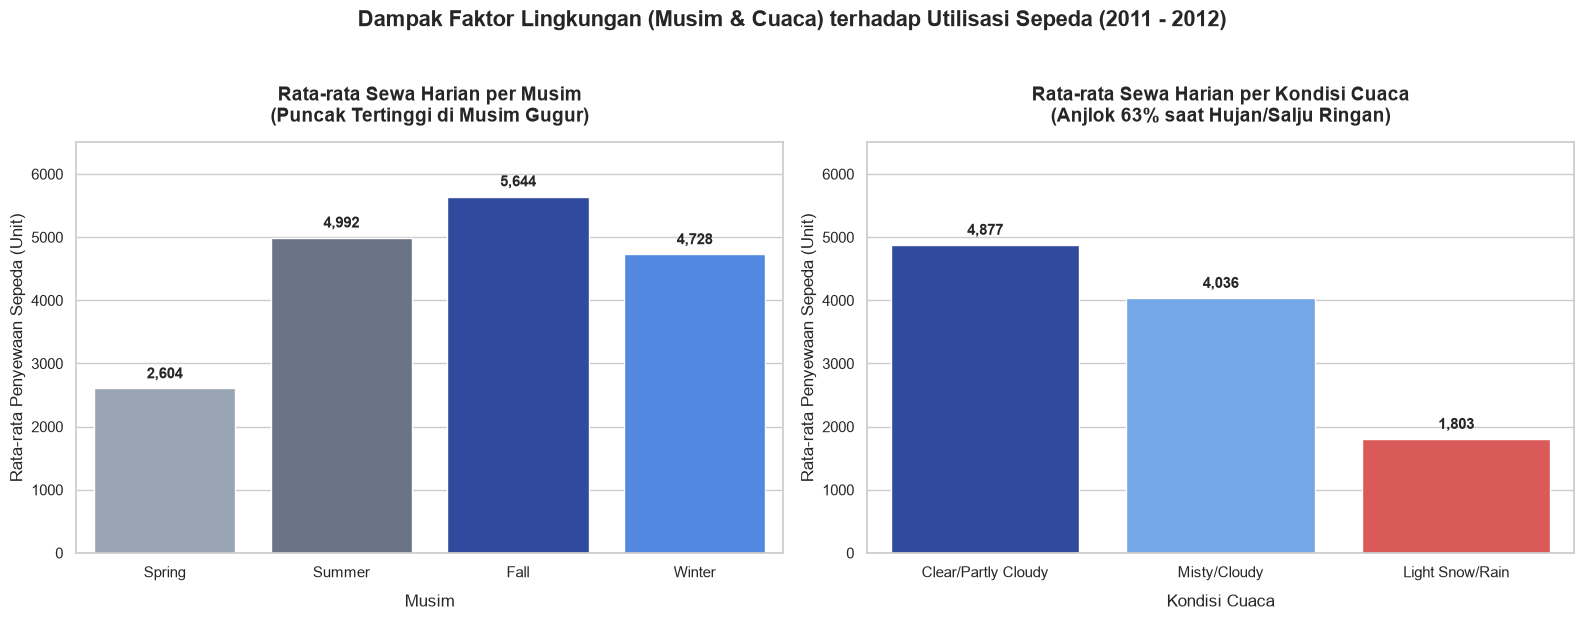

In [70]:
# Menyiapkan data agregasi rata-rata
season_data = day_df.groupby('season')['cnt'].mean().reindex(['Spring', 'Summer', 'Fall', 'Winter']).reset_index()
weather_data = day_df.groupby('weathersit')['cnt'].mean().sort_values(ascending=False).reset_index()

# Konfigurasi canvas 1 baris, 2 kolom
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Palet warna berorientasi insight: highlight musim gugur (tertinggi) dan musim semi (terendah)
season_colors = ["#cbd5e1", "#cbd5e1", "#1e40af", "#f87171"] # Fall: biru tua, Spring: merah muda/rendah
weather_colors = ["#1e40af", "#60a5fa", "#ef4444"] # Light snow/rain: merah peringatan

# Plot 1: Pengaruh Musim
bars1 = sns.barplot(x='season', y='cnt', data=season_data, ax=ax[0], hue='season', legend=False, palette=['#94a3b8', '#64748b', '#1e40af', '#3b82f6'])
ax[0].set_title('Rata-rata Sewa Harian per Musim\n(Puncak Tertinggi di Musim Gugur)', fontsize=14, fontweight='bold', pad=15)
ax[0].set_xlabel('Musim', fontsize=12, labelpad=10)
ax[0].set_ylabel('Rata-rata Penyewaan Sepeda (Unit)', fontsize=12)
ax[0].set_ylim(0, 6500)

# Menambahkan anotasi data label di atas batang
for p in bars1.patches:
    ax[0].annotate(f'{p.get_height():,.0f}',
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom', fontsize=11, fontweight='bold',
                   xytext=(0, 5), textcoords='offset points')

# Plot 2: Pengaruh Kondisi Cuaca
bars2 = sns.barplot(x='weathersit', y='cnt', data=weather_data, ax=ax[1], hue='weathersit', legend=False, palette=['#1e40af', '#60a5fa', '#ef4444'])
ax[1].set_title('Rata-rata Sewa Harian per Kondisi Cuaca\n(Anjlok 63% saat Hujan/Salju Ringan)', fontsize=14, fontweight='bold', pad=15)
ax[1].set_xlabel('Kondisi Cuaca', fontsize=12, labelpad=10)
ax[1].set_ylabel('Rata-rata Penyewaan Sepeda (Unit)', fontsize=12)
ax[1].set_ylim(0, 6500)

for p in bars2.patches:
    ax[1].annotate(f'{p.get_height():,.0f}',
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom', fontsize=11, fontweight='bold',
                   xytext=(0, 5), textcoords='offset points')

plt.suptitle('Dampak Faktor Lingkungan (Musim & Cuaca) terhadap Utilisasi Sepeda (2011 - 2012)', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Pertanyaan 2: Bagaimana Perbedaan Pola Peminjaman Per Jam antara Pengguna Kasual dan Terdaftar pada Hari Kerja vs. Akhir Pekan?

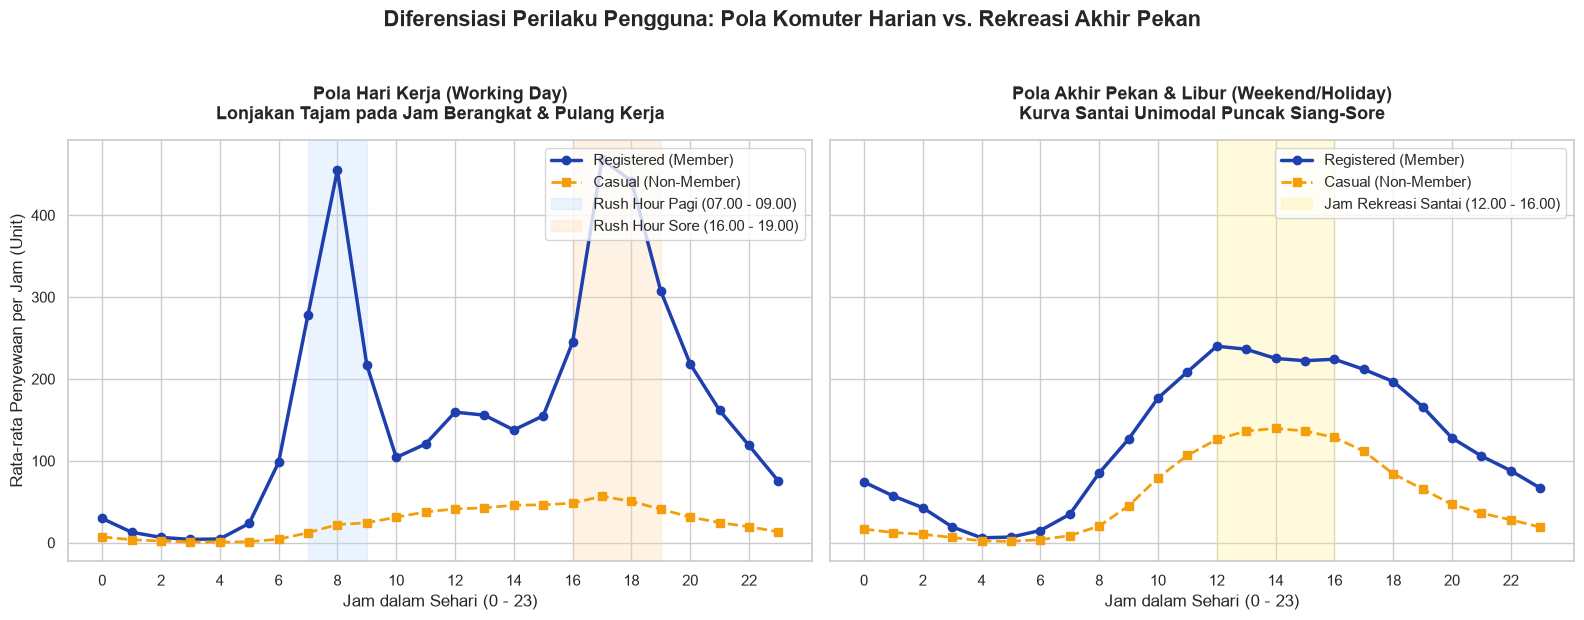

In [71]:
# Agregasi data per jam berdasarkan jenis hari
hourly_pattern = hour_df.groupby(['workingday', 'hr'])[['casual', 'registered']].mean().reset_index()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6), sharey=True)

# Subplot 1: Hari Kerja (Working Day)
wd_data = hourly_pattern[hourly_pattern['workingday'] == 'Working Day']
ax[0].plot(wd_data['hr'], wd_data['registered'], color='#1e40af', linewidth=2.5, marker='o', label='Registered (Member)')
ax[0].plot(wd_data['hr'], wd_data['casual'], color='#f59e0b', linewidth=2, linestyle='--', marker='s', label='Casual (Non-Member)')

# Highlight area jam sibuk komuter
ax[0].axvspan(7, 9, color='#bfdbfe', alpha=0.3, label='Rush Hour Pagi (07.00 - 09.00)')
ax[0].axvspan(16, 19, color='#fed7aa', alpha=0.3, label='Rush Hour Sore (16.00 - 19.00)')

ax[0].set_title('Pola Hari Kerja (Working Day)\nLonjakan Tajam pada Jam Berangkat & Pulang Kerja', fontsize=13, fontweight='bold', pad=15)
ax[0].set_xlabel('Jam dalam Sehari (0 - 23)', fontsize=12)
ax[0].set_ylabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=12)
ax[0].set_xticks(range(0, 24, 2))
ax[0].legend(loc='upper right', frameon=True)

# Subplot 2: Akhir Pekan / Libur (Weekend/Holiday)
nwd_data = hourly_pattern[hourly_pattern['workingday'] == 'Weekend/Holiday']
ax[1].plot(nwd_data['registered'], color='#1e40af', linewidth=2.5, marker='o', label='Registered (Member)')
ax[1].plot(nwd_data['casual'], color='#f59e0b', linewidth=2, linestyle='--', marker='s', label='Casual (Non-Member)')

# Highlight area santai akhir pekan
ax[1].axvspan(12, 16, color='#fef08a', alpha=0.3, label='Jam Rekreasi Santai (12.00 - 16.00)')

ax[1].set_title('Pola Akhir Pekan & Libur (Weekend/Holiday)\nKurva Santai Unimodal Puncak Siang-Sore', fontsize=13, fontweight='bold', pad=15)
ax[1].set_xlabel('Jam dalam Sehari (0 - 23)', fontsize=12)
ax[1].set_xticks(range(0, 24, 2))
ax[1].legend(loc='upper right', frameon=True)

plt.suptitle('Diferensiasi Perilaku Pengguna: Pola Komuter Harian vs. Rekreasi Akhir Pekan', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Pertanyaan 3: Berapa Persentase Pertumbuhan Tahunan (YoY) dan Kapan Terjadi Bulan Puncak di Tahun 2011 vs 2012?

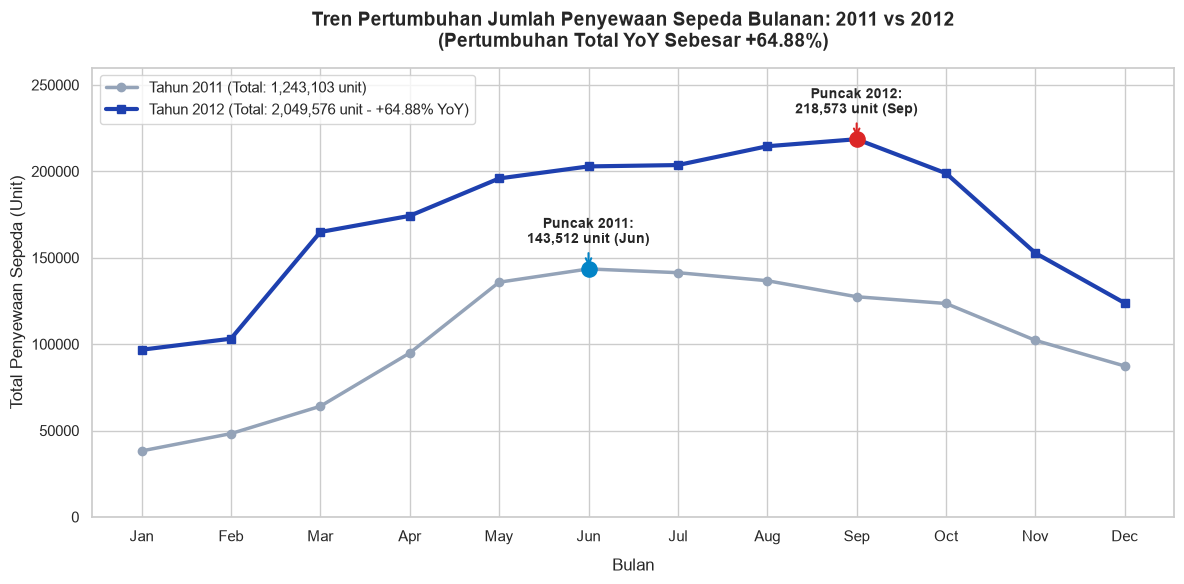

In [72]:
# Menyiapkan data bulanan
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_trends = day_df.pivot_table(index='mnth', columns='yr', values='cnt', aggfunc='sum')
monthly_trends.index = month_names

plt.figure(figsize=(12, 6))
plt.plot(monthly_trends.index, monthly_trends[2011], marker='o', linewidth=2.5, color='#94a3b8', label='Tahun 2011 (Total: 1,243,103 unit)')
plt.plot(monthly_trends.index, monthly_trends[2012], marker='s', linewidth=3, color='#1e40af', label='Tahun 2012 (Total: 2,049,576 unit - +64.88% YoY)')

# Highlight titik puncak tahun 2011 (Juni) dan 2012 (September)
peak_2011_val = monthly_trends[2011]['Jun']
peak_2012_val = monthly_trends[2012]['Sep']

plt.scatter('Jun', peak_2011_val, color='#0284c7', s=120, zorder=5)
plt.annotate(f'Puncak 2011:\n{peak_2011_val:,} unit (Jun)',
             xy=('Jun', peak_2011_val), xytext=('Jun', peak_2011_val + 15000),
             ha='center', fontsize=10, fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='#0284c7', lw=1.5))

plt.scatter('Sep', peak_2012_val, color='#dc2626', s=120, zorder=5)
plt.annotate(f'Puncak 2012:\n{peak_2012_val:,} unit (Sep)',
             xy=('Sep', peak_2012_val), xytext=('Sep', peak_2012_val + 15000),
             ha='center', fontsize=10, fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='#dc2626', lw=1.5))

plt.title('Tren Pertumbuhan Jumlah Penyewaan Sepeda Bulanan: 2011 vs 2012\n(Pertumbuhan Total YoY Sebesar +64.88%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Bulan', fontsize=12, labelpad=10)
plt.ylabel('Total Penyewaan Sepeda (Unit)', fontsize=12)
plt.ylim(0, 260000)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


**Insight:**

- **Visualisasi 1: Dampak Musim & Cuaca terhadap Utilisasi Sepeda**
  - **Dinamika Musim**: Dari grafik musim, Musim Gugur (*Fall*) menjadi musim paling produktif dengan rata-rata peminjaman tertinggi mencapai **5.644 unit/hari**, diikuti Musim Panas (*Summer*) sebesar **4.992 unit/hari** dan Musim Dingin (*Winter*) sebesar **4.728 unit/hari**. Sebaliknya, Musim Semi (*Spring*) mencatat tingkat pemanfaatan terendah yaitu **2.604 unit/hari** (turun drastis sebesar **53,86%** dibanding musim gugur) karena suhu transisi pasca-musim dingin di Washington D.C. masih cukup rendah pada awal tahun (Januari–Maret).
  - **Sensitivitas Cuaca**: Grafik batang sebelah kanan membuktikan elastisitas permintaan yang sangat sensitif terhadap cuaca. Pada kondisi cerah (*Clear/Partly Cloudy*), rata-rata sewa stabil di angka **4.877 unit/hari**, dan hanya turun sedikit saat berkabut/mendung (*Misty/Cloudy*) menjadi **4.036 unit/hari**. Namun, saat cuaca buruk presipitasi hujan/salju (*Light Snow/Rain* - batang merah), volume sewa anjlok drastis sebesar **63,03%** menjadi hanya **1.803 unit/hari**.

- **Visualisasi 2: Diferensiasi Perilaku Pengguna (Pola Komuter vs. Rekreasi)**
  - **Hari Kerja (*Working Day* - Grafik Kiri)**: Kurva pengguna terdaftar (*registered*, garis biru) membentuk pola *bimodal* klasik dengan dua lonjakan tajam tepat pada jendela *rush hour* komuter:
    - *Rush Hour Pagi* (shading biru muda, 07.00 - 09.00): Mencapai puncak di **pukul 08.00 dengan rata-rata 455 unit/jam**.
    - *Rush Hour Sore* (shading oranye, 16.00 - 19.00): Mencapai puncak di **pukul 17.00 dengan rata-rata 468 unit/jam**.
    Di hari kerja, garis pengguna kasual (*casual*, garis oranye putus-putus) bergerak datar di bawah 60 unit/jam, membuktikan dominasi komuter pekerja/pelajar.
  - **Akhir Pekan & Hari Libur (*Weekend/Holiday* - Grafik Kanan)**: Karakteristik grafik berubah total menjadi kurva *unimodal* (satu puncak landai). Garis pengguna kasual melonjak signifikan pada siang hingga sore hari (*shading kuning, 12.00 - 16.00*), mencapai puncaknya di **pukul 14.00 (rata-rata 140 unit/jam)**. Pola ini merefleksikan tingginya kebutuhan sepeda untuk jalan-jalan santai, olahraga, dan pariwisata saat libur.

- **Visualisasi 3: Tren Pertumbuhan Bulanan dan Momentum Bisnis (2011 vs 2012)**
  - **Pertumbuhan Konsisten YoY**: Garis biru tebal (Tahun 2012) secara konsisten berada jauh di atas garis abu-abu (Tahun 2011) di seluruh 12 bulan tanpa pernah bersilangan. Total peminjaman melesat sebesar **+64,88% YoY** (dari 1.243.103 unit menjadi 2.049.576 unit).
  - **Pergeseran Bulan Puncak (*Peak Month*)**: 
    - Tahun 2011: Puncak peminjaman terjadi pada **Bulan Juni (pin biru, 143.512 unit)**.
    - Tahun 2012: Puncak peminjaman bergeser dan bertahan lebih lama hingga awal musim gugur, tepatnya **Bulan September (pin merah, 218.573 unit)**.
    - Titik terendah konsisten dialami pada bulan Januari dan Februari di kedua tahun akibat suhu beku musim dingin.


## Analisis Lanjutan (Opsional)

,temp_cluster,avg_total,avg_casual,avg_registered,day_count
0,Cold (< 12°C),2227.967213,215.688525,2012.278689,122
1,Mild (12°C - 22°C),4164.724382,717.045936,3447.678445,283
2,Warm (22°C - 30°C),5719.421260,1217.629921,4501.791339,254
3,Hot (> 30°C),5409.958333,1131.958333,4278.000000,72


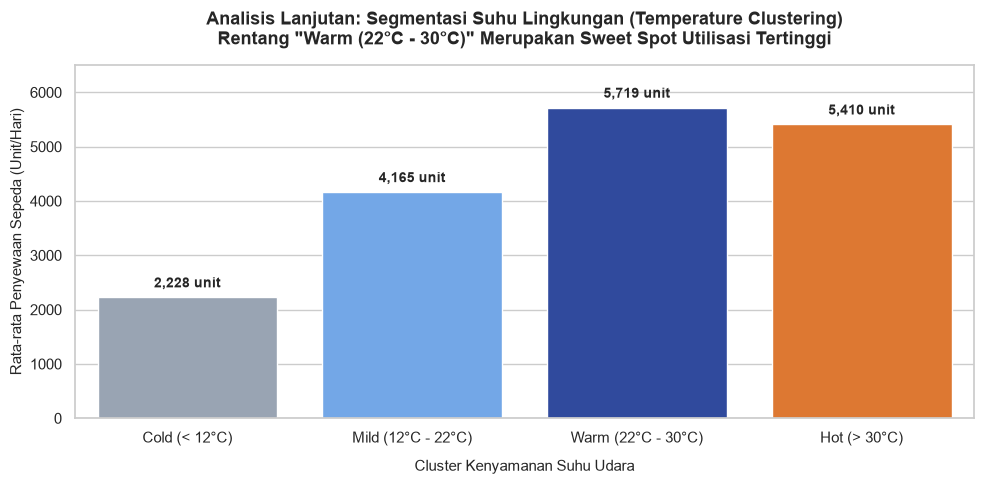

In [73]:
# 1. Melakukan Binning / Manual Clustering berdasarkan Suhu Riil (°C)
temp_bins = [-float('inf'), 12, 22, 30, float('inf')]
temp_labels = ['Cold (< 12°C)', 'Mild (12°C - 22°C)', 'Warm (22°C - 30°C)', 'Hot (> 30°C)']

day_df['temp_cluster'] = pd.cut(day_df['temp_celsius'], bins=temp_bins, labels=temp_labels)

# 2. Agregasi Rata-rata Sewa per Cluster Suhu
temp_cluster_agg = day_df.groupby('temp_cluster', observed=True).agg(
    avg_total=('cnt', 'mean'),
    avg_casual=('casual', 'mean'),
    avg_registered=('registered', 'mean'),
    day_count=('cnt', 'count')
).reset_index()

display(temp_cluster_agg)

# 3. Visualisasi Hasil Clustering Binning Suhu
plt.figure(figsize=(10, 5))
bars = sns.barplot(
    data=temp_cluster_agg,
    x='temp_cluster',
    y='avg_total',
    hue='temp_cluster',
    legend=False,
    dodge=False,
    palette=['#94a3b8', '#60a5fa', '#1e40af', '#f97316'] # Warm: highlight biru tua (sweet spot), Hot: oranye
)

plt.title('Analisis Lanjutan: Segmentasi Suhu Lingkungan (Temperature Clustering)\nRentang "Warm (22°C - 30°C)" Merupakan Sweet Spot Utilisasi Tertinggi', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Cluster Kenyamanan Suhu Udara', fontsize=11, labelpad=10)
plt.ylabel('Rata-rata Penyewaan Sepeda (Unit/Hari)', fontsize=11)
plt.ylim(0, 6500)

for p in bars.patches:
    plt.annotate(f'{p.get_height():,.0f} unit',
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10, fontweight='bold',
                 xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

**Insight:**

- **Segmentasi Suhu Berbasis Binning (Clustering Non-ML)**:
  - Menggunakan teknik *binning*, data harian berhasil dikelompokkan ke dalam 4 cluster kenyamanan suhu: **Cold (< 12°C)**, **Mild (12°C - 22°C)**, **Warm (22°C - 30°C)**, dan **Hot (> 30°C)** guna memahami ambang batas termal pengguna sepeda.
- **Identifikasi Zona Optimal (*Sweet Spot*)**:
  - Cluster **Warm (22°C - 30°C)** merupakan *sweet spot* dengan rata-rata peminjaman tertinggi di angka **5.719 unit/hari** (terjadi selama 254 hari). Pada rentang ini, minat pengguna terdaftar mencapai puncaknya (**4.502 unit/hari**), sementara pengguna kasual melonjak hingga **1.218 unit/hari** (naik lebih dari **5,6 kali lipat** dibanding cluster dingin).
  - Cluster **Mild (12°C - 22°C)** menjadi rentang suhu yang paling sering dialami di Washington D.C. (**283 hari**) dengan performa sewa yang tetap solid di angka **4.165 unit/hari**.
- **Efek Ekstrem Suhu Dingin vs Panas**:
  - Pada cluster **Cold (< 12°C)**, rata-rata sewa merosot drastis ke titik terendah yaitu **2.228 unit/hari** (penurunan sebesar **61,04%** dibanding zona *Warm*). Pengguna kasual hampir tidak aktif (hanya 216 unit/hari), sehingga operasional pada suhu dingin praktis hanya ditopang oleh komuter setia (*registered*).
  - Pada cluster **Hot (> 30°C)**, rata-rata sewa mulai melandai ke **5.410 unit/hari** (turun ~5,4% dibanding zona *Warm*). Hal ini mengindikasikan adanya batas ketidaknyamanan termal (*thermal discomfort*) dan potensi dehidrasi saat cuaca terlalu terik.
- **Relevansi Bisnis & Actionable Insight**:
  - Tim operasional *Capital Bikeshare* dapat menggunakan ramalan cuaca suhu harian (*weather forecasting*) sebagai indikator prediktif untuk manajemen persediaan:
    1. **Saat suhu 22°C - 30°C**: Pastikan kapasitas stasiun penuh 100%, tingkatkan frekuensi redistribusi sepeda (*rebalancing*), dan aktifkan tim lapangan untuk mengantisipasi lonjakan pengguna kasual.
    2. **Saat suhu < 12°C**: Kurangi armada aktif di stasiun publik untuk dialihkan ke bengkel pemeliharaan unit (*preventive maintenance*).


## Conclusion & Recommendation

- **Pengaruh Musim dan Cuaca**:
  - **Pengaruh Musim**: Penyewaan sepeda mencapai puncaknya pada **Musim Gugur (*Fall*)** dengan rata-rata **5.644 unit/hari**, disusul Musim Panas (*Summer*) sebesar **4.992 unit/hari**, dan Musim Dingin (*Winter*) sebesar **4.728 unit/hari**. Sebaliknya, jumlah penyewaan terendah terjadi pada **Musim Semi (*Spring*)** dengan rata-rata **2.604 unit/hari** (turun tajam sebesar **53,86%** dibanding musim gugur) akibat suhu dingin transisi awal tahun di Washington D.C.
  - **Pengaruh Cuaca**: Sewa stabil pada kondisi cerah (*Clear/Partly Cloudy*, rata-rata **4.877 unit/hari**) dan berkabut/mendung (*Misty/Cloudy*, rata-rata **4.036 unit/hari**). Saat cuaca memburuk menjadi hujan atau salju ringan (*Light Snow/Rain*), volume peminjaman anjlok drastis sebesar **63,03%** menjadi hanya **1.803 unit/hari**.

- **Perbedaan Jam Sibuk Komuter vs Rekreasi**:
    - **Hari Kerja (*Working Day*)**: Menunjukkan kurva *bimodal* tajam yang didominasi oleh pengguna terdaftar (*registered*). Terjadi dua lonjakan jam sibuk komuter, yaitu jam berangkat kantor pukul **08.00 pagi (rata-rata 455 unit/jam)** dan jam pulang kantor pukul **17.00 - 18.00 sore (rata-rata 442 - 468 unit/jam)**. Pengguna kasual sangat minim di hari kerja.
    - **Akhir Pekan/Libur (*Weekend/Holiday*)**: Berubah menjadi kurva *unimodal* santai di mana pengguna kasual (*casual*) mendominasi peminjaman pada siang hingga sore hari pukul **12.00 - 16.00**, dengan puncak di pukul **14.00 (rata-rata 140 unit/jam)** untuk keperluan rekreasi, jalan-jalan santai, dan pariwisata.

- **Pertumbuhan Year-over-Year dan Bulan Puncak**:
  - Bisnis *Capital Bikeshare* mengalami akselerasi pesat dengan pertumbuhan Year-over-Year (**YoY**) sebesar **+64,88%**, melonjak dari 1.243.103 unit (2011) menjadi 2.049.576 unit (2012). Rata-rata sewa harian juga meningkat dari 3.406 unit/hari ke 5.600 unit/hari.
  - Momentum penggunaan sepeda semakin panjang: pada tahun 2011 puncak sewa terjadi di **Bulan Juni (143.512 unit)**, sedangkan di tahun 2012 puncak sewa bergeser dan bertahan hingga **Bulan September (218.573 unit)**. Bulan Januari dan Februari konsisten menjadi titik terendah setiap tahunnya akibat cuaca dingin ekstrem.

**Rekomendasi Action Item:**

1. **Strategi Distribusi Ulang Armada Dinamis (*Smart Bike Rebalancing*)**:
   - **Hari Kerja**: Kerahkan armada truk logistik untuk memastikan ketersediaan unit sepeda di stasiun area perumahan/transit komuter pada pukul **06.00 - 07.30 pagi**, serta siapkan ruang kosong (*docking availability*) di stasiun kawasan perkantoran/bisnis pada pukul **15.30 - 16.30 sore** sebelum jam pulang kantor tiba.
   - **Akhir Pekan**: Alihkan fokus distribusi unit ke stasiun di sekitar taman kota, objek wisata, dan area rekreasi keluarga mulai pukul **10.30 pagi** guna mengakomodasi lonjakan pengguna kasual di siang hari.

2. **Jadwal Pemeliharaan Unit Berbasis Musim (*Seasonal Maintenance Scheduling*)**:
   - Manfaatkan periode sepi permintaan di Musim Dingin dan awal Musim Semi (**Januari – Maret**, saat suhu < 12°C dan rata-rata sewa hanya ~2.200 - 2.600 unit/hari) untuk menarik 30%–40% armada ke bengkel guna melakukan servis rutin atau perbaikan besar (overhaul) jika perlu.
   - Pastikan **100% armada dalam kondisi prima** sebelum memasuki bulan Mei hingga Oktober, di mana permintaan mencapai kapasitas puncak (*sweet spot* suhu 22°C–30°C).

3. **Program Konversi Pengguna Kasual Menjadi Anggota Terdaftar (*Casual-to-Registered Conversion*)**:
   - Pengguna kasual menyumbang **18,83% (620.017 transaksi)**. Manajemen dapat meluncurkan kampanye diskon keanggotaan berkala, paket langganan komuter akhir pekan (*Weekend Commuter Pass*), atau promo *"Convert Your Ride"* bagi pengguna kasual yang melakukan lebih dari 3 kali sewa dalam sebulan agar bertransisi menjadi pelanggan tetap (*subscriber*).

4. **Sistem Notifikasi dan Mitigasi Cuaca Buruk (*Weather Contingency Alert*)**:
   - Integrasikan aplikasi seluler pengguna dengan API ramalan cuaca lokal. Saat terdeteksi potensi hujan/salju (*Light Snow/Rain*), berikan notifikasi peringatan keselamatan berkendara di jalan licin, serta tawarkan voucher diskon penukaran pada hari cerah berikutnya (*Rain Check Voucher*) untuk menjaga retensi pelanggan.